# ML Assignment 2 — Online Shoppers Purchasing Intention

**Dataset:** [Online Shoppers Purchasing Intention](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset)
(UCI Machine Learning Repository, id 468, licence CC BY 4.0). Each row is one browsing session on an
e-commerce site; the target `Revenue` says whether the session ended in a purchase.

Notebook sections:
1. Load and inspect the data
2. Train / test split and preprocessing design
3. Train, tune and evaluate the five classifiers
4. Comparison and observations


## 1. Load and inspect the data

The raw CSV is committed under `data/` so this notebook runs without internet access (for example on BITS Virtual Lab).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

RANDOM_STATE = 42
DATA_PATH = Path("data") / "online_shoppers_intention.csv"
RESULTS_DIR = Path("results")
MODEL_DIR = Path("model")
RESULTS_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
print("python      ", sys.version.split()[0])
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("matplotlib  ", matplotlib.__version__)
print("seaborn     ", sns.__version__)

python       3.12.13
numpy        2.5.4
pandas       3.1.0
scikit-learn 1.9.1
matplotlib   3.11.2
seaborn      0.13.2


In [2]:
raw = pd.read_csv(DATA_PATH)
print(f"rows = {raw.shape[0]:,}   columns = {raw.shape[1]}")
raw.head()

rows = 12,330   columns = 18


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

### Column groups

| Group | Columns | Meaning |
|---|---|---|
| Page counts | `Administrative`, `Informational`, `ProductRelated` | number of pages of each type visited in the session |
| Page durations | `Administrative_Duration`, `Informational_Duration`, `ProductRelated_Duration` | seconds spent on each page type |
| Google Analytics metrics | `BounceRates`, `ExitRates`, `PageValues` | averages over the pages visited in the session |
| Calendar | `SpecialDay`, `Month`, `Weekend` | closeness to a special day (0–1), month of the visit, weekend flag |
| Visitor / technical | `OperatingSystems`, `Browser`, `Region`, `TrafficType`, `VisitorType` | integer-coded categories and visitor type |
| **Target** | `Revenue` | `True` if the session ended with a transaction |

The integer-coded columns (`OperatingSystems`, `Browser`, `Region`, `TrafficType`) are category labels, not
quantities, so they will be treated as categorical features in the next section.

In [4]:
TARGET = "Revenue"
NUMERIC_FEATURES = [
    "Administrative", "Administrative_Duration",
    "Informational", "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration",
    "BounceRates", "ExitRates", "PageValues", "SpecialDay",
]
CATEGORICAL_FEATURES = [
    "Month", "OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType", "Weekend",
]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

assert set(FEATURES) | {TARGET} == set(raw.columns), "column list does not match the file"
print(f"{len(NUMERIC_FEATURES)} numeric + {len(CATEGORICAL_FEATURES)} categorical = {len(FEATURES)} input features")

10 numeric + 7 categorical = 17 input features


### Data quality checks

In [5]:
missing = raw.isna().sum()
print("missing values per column:")
print(missing[missing > 0] if missing.any() else "  none")

n_dup = raw.duplicated().sum()
print(f"\nexact duplicate rows: {n_dup}  ({n_dup / len(raw):.2%})")
print("Duplicates are kept: the file has no session id, and sessions that bounce on a single page")
print("legitimately produce identical rows, so they are treated as genuine observations.")

missing values per column:
  none

exact duplicate rows: 125  (1.01%)
Duplicates are kept: the file has no session id, and sessions that bounce on a single page
legitimately produce identical rows, so they are treated as genuine observations.


         sessions  percent
Revenue                   
False       10422    84.53
True         1908    15.47


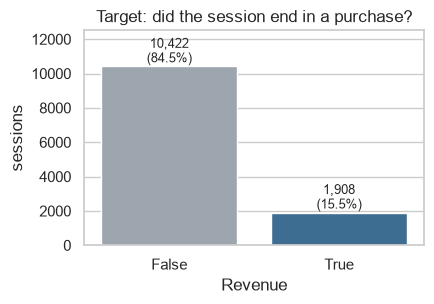

In [6]:
target_counts = raw[TARGET].value_counts()
target_pct = raw[TARGET].value_counts(normalize=True).mul(100).round(2)
target_table = pd.DataFrame({"sessions": target_counts, "percent": target_pct})
print(target_table)

fig, ax = plt.subplots(figsize=(4.5, 3.2))
sns.barplot(x=target_table.index.astype(str), y=target_table["sessions"], hue=target_table.index.astype(str),
            palette=["#9aa5b1", "#2f6f9f"], legend=False, ax=ax)
for i, v in enumerate(target_table["sessions"]):
    ax.text(i, v, f"{v:,}\n({target_table['percent'].iloc[i]:.1f}%)", ha="center", va="bottom", fontsize=9)
ax.set(title="Target: did the session end in a purchase?", xlabel="Revenue", ylabel="sessions")
ax.set_ylim(0, target_table["sessions"].max() * 1.2)
plt.tight_layout()
fig.savefig(RESULTS_DIR / "target_distribution.png", dpi=120)
plt.show()

The classes are imbalanced: only about one session in six converts. Plain accuracy is therefore a weak
yardstick (always predicting "no purchase" scores about 85 %). The AUC, F1 and especially the Matthews
Correlation Coefficient will be the metrics to watch when the models are compared.

In [7]:
raw[NUMERIC_FEATURES].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315,3.322,0.0,0.000,1.000,4.000,27.000
Administrative_Duration,12330.0,80.819,176.779,0.0,0.000,7.500,93.256,3398.750
Informational,12330.0,0.504,1.270,0.0,0.000,0.000,0.000,24.000
Informational_Duration,12330.0,34.472,140.749,0.0,0.000,0.000,0.000,2549.375
ProductRelated,12330.0,31.731,44.476,0.0,7.000,18.000,38.000,705.000
ProductRelated_Duration,12330.0,1194.746,1913.669,0.0,184.138,598.937,1464.157,63973.522
BounceRates,12330.0,0.022,0.048,0.0,0.000,0.003,0.017,0.200
ExitRates,12330.0,0.043,0.049,0.0,0.014,0.025,0.050,0.200
PageValues,12330.0,5.889,18.568,0.0,0.000,0.000,0.000,361.764
SpecialDay,12330.0,0.061,0.199,0.0,0.000,0.000,0.000,1.000


In [8]:
for col in CATEGORICAL_FEATURES:
    vc = raw[col].value_counts()
    top = ", ".join(f"{k}: {int(v):,}" for k, v in vc.head(6).items())
    print(f"{col:17s} {vc.size:2d} levels  ->  {top}{', ...' if vc.size > 6 else ''}")

Month             10 levels  ->  May: 3,364, Nov: 2,998, Mar: 1,907, Dec: 1,727, Oct: 549, Sep: 448, ...
OperatingSystems   8 levels  ->  2: 6,601, 1: 2,585, 3: 2,555, 4: 478, 8: 79, 6: 19, ...
Browser           13 levels  ->  2: 7,961, 1: 2,462, 4: 736, 5: 467, 6: 174, 10: 163, ...
Region             9 levels  ->  1: 4,780, 3: 2,403, 4: 1,182, 2: 1,136, 6: 805, 7: 761, ...
TrafficType       20 levels  ->  2: 3,913, 1: 2,451, 3: 2,052, 4: 1,069, 13: 738, 10: 450, ...
VisitorType        3 levels  ->  Returning_Visitor: 10,551, New_Visitor: 1,694, Other: 85
Weekend            2 levels  ->  False: 9,462, True: 2,868


### Numeric feature distributions

Most numeric features are heavily right-skewed (many zero-valued sessions, a long tail of long sessions),
which is why the pipelines in the next section standardise them before the distance-based and linear models.

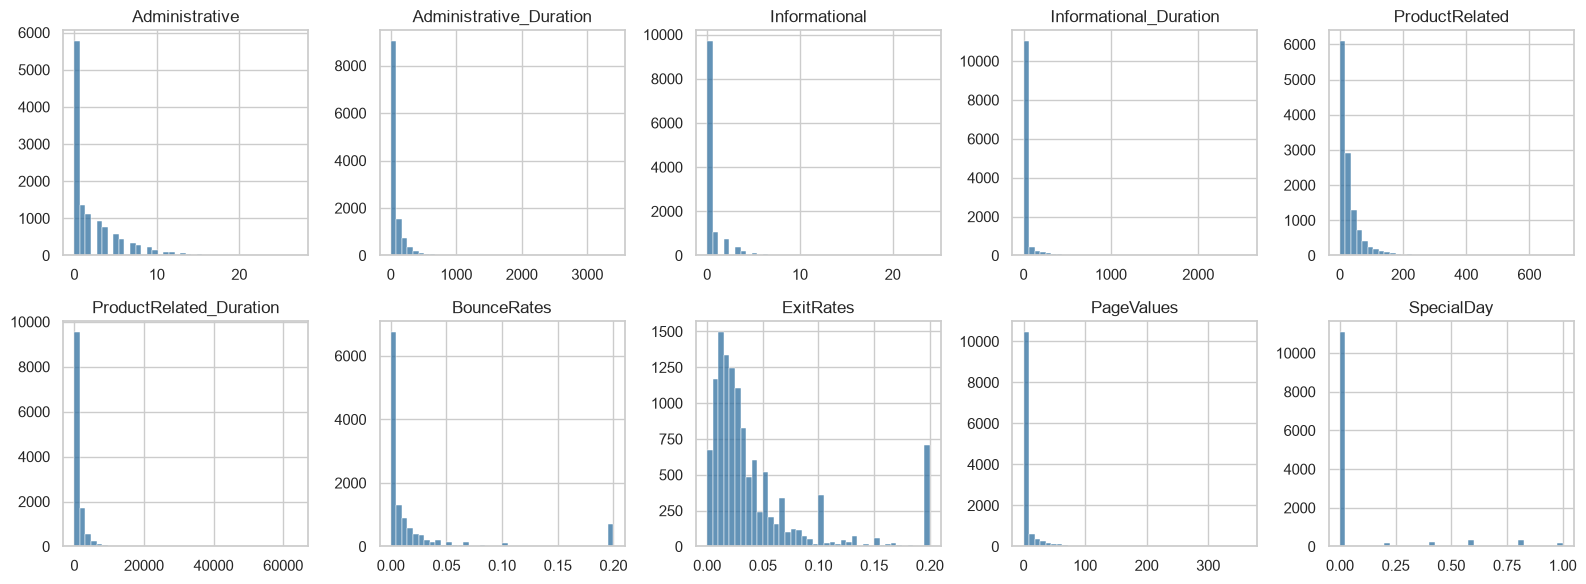

In [9]:
fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for ax, col in zip(axes.ravel(), NUMERIC_FEATURES):
    sns.histplot(raw[col], bins=40, ax=ax, color="#2f6f9f", edgecolor=None)
    ax.set(title=col, xlabel="", ylabel="")
plt.tight_layout()
fig.savefig(RESULTS_DIR / "numeric_distributions.png", dpi=120)
plt.show()

In [10]:
conv_by_visitor = raw.groupby("VisitorType")[TARGET].mean().mul(100).round(2)
conv_by_month = raw.groupby("Month")[TARGET].mean().mul(100).round(2).sort_values(ascending=False)
print("conversion rate (%) by visitor type:\n", conv_by_visitor.to_string(), "\n")
print("conversion rate (%) by month:\n", conv_by_month.to_string())

conversion rate (%) by visitor type:
 VisitorType
New_Visitor          24.91
Other                18.82
Returning_Visitor    13.93 

conversion rate (%) by month:
 Month
Nov     25.35
Oct     20.95
Sep     19.20
Aug     17.55
Jul     15.28
Dec     12.51
May     10.85
June    10.07
Mar     10.07
Feb      1.63


### Assignment constraints check

The assignment requires at least 12 input features and at least 500 instances.

In [11]:
MIN_FEATURES, MIN_ROWS = 12, 500
assert len(FEATURES) >= MIN_FEATURES, f"need >= {MIN_FEATURES} features, got {len(FEATURES)}"
assert len(raw) >= MIN_ROWS, f"need >= {MIN_ROWS} rows, got {len(raw)}"

profile_lines = [
    "Online Shoppers Purchasing Intention (UCI id 468)",
    f"rows: {len(raw)}",
    f"input features: {len(FEATURES)} ({len(NUMERIC_FEATURES)} numeric, {len(CATEGORICAL_FEATURES)} categorical)",
    f"target: {TARGET} (binary)",
    f"positive class (Revenue=True): {int(target_counts.get(True, 0))} ({target_pct.get(True, 0):.2f}%)",
    f"negative class (Revenue=False): {int(target_counts.get(False, 0))} ({target_pct.get(False, 0):.2f}%)",
    f"missing values: {int(missing.sum())}",
    f"exact duplicate rows (kept): {int(n_dup)}",
    f"constraint check: features >= {MIN_FEATURES} and rows >= {MIN_ROWS} -> PASS",
]
(RESULTS_DIR / "data_profile.txt").write_text("\n".join(profile_lines) + "\n")
print("\n".join(profile_lines))

Online Shoppers Purchasing Intention (UCI id 468)
rows: 12330
input features: 17 (10 numeric, 7 categorical)
target: Revenue (binary)
positive class (Revenue=True): 1908 (15.47%)
negative class (Revenue=False): 10422 (84.53%)
missing values: 0
exact duplicate rows (kept): 125
constraint check: features >= 12 and rows >= 500 -> PASS


## 2. Train / test split and preprocessing design

**Split.** 80 % of the sessions are used for training (including cross-validated tuning) and 20 % are held
out as the test set. The split is *stratified* on `Revenue` so both parts keep the same 15 % purchase rate,
and `random_state=42` makes it reproducible. The held-out part is written to `test_data.csv` with the raw
feature columns plus the target, exactly as the Streamlit app expects an upload.

**Preprocessing.** One `ColumnTransformer` handles both column groups:

| Columns | Transformer | Why |
|---|---|---|
| 10 numeric | `StandardScaler` | KNN and SVM are distance-based and logistic regression is scale-sensitive; the skewed durations would otherwise dominate |
| 7 categorical | `OneHotEncoder(handle_unknown="ignore")` | integer codes such as `Browser=2` are labels, not quantities; unseen levels in an upload become all-zero instead of raising |

The transformer is **fit on the training split only** and lives inside each model's `Pipeline`, so test
statistics never leak into the fitted scaler or encoder, and the saved pipeline accepts a raw CSV directly.
Scaling is a monotone transform, so it is harmless for the decision tree.

In [12]:
import json
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X = raw[FEATURES]
y = raw[TARGET].astype(int)          # True/False -> 1/0 (1 = purchase, the positive class)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

split_summary = pd.DataFrame({
    "rows": [len(X_train), len(X_test)],
    "positive": [int(y_train.sum()), int(y_test.sum())],
    "positive_rate_%": [round(100 * y_train.mean(), 2), round(100 * y_test.mean(), 2)],
}, index=["train", "test"])
print(split_summary)

       rows  positive  positive_rate_%
train  9864      1526            15.47
test   2466       382            15.49


In [13]:
# Held-out test set, saved with raw features + target for the Streamlit app and the repo.
test_df = X_test.copy()
test_df[TARGET] = raw.loc[X_test.index, TARGET]   # keep the original True/False values
test_df.to_csv("test_data.csv", index=False)
print(f"test_data.csv written: {test_df.shape[0]:,} rows x {test_df.shape[1]} columns")

# Feature schema: lets the app validate an uploaded CSV before scoring it.
schema = {
    "target": TARGET,
    "positive_label": True,
    "numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "categorical_levels": {c: sorted(map(str, raw[c].unique())) for c in CATEGORICAL_FEATURES},
    "random_state": RANDOM_STATE,
    "test_size": 0.20,
}
(MODEL_DIR / "feature_schema.json").write_text(json.dumps(schema, indent=2))
print("model/feature_schema.json written")

test_data.csv written: 2,466 rows x 18 columns
model/feature_schema.json written


In [14]:
def make_preprocessor():
    """Fresh, unfitted preprocessing step (one instance per model pipeline)."""
    return ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), NUMERIC_FEATURES),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )

prep = make_preprocessor().fit(X_train)
n_out = len(prep.get_feature_names_out())
print(f"preprocessed feature count: {len(NUMERIC_FEATURES)} scaled numeric + "
      f"{n_out - len(NUMERIC_FEATURES)} one-hot columns = {n_out}")

preprocessed feature count: 10 scaled numeric + 65 one-hot columns = 75


### Validation of the split and preprocessing

Checks that must hold before any model is trained:

1. `test_data.csv` reloads with the same dtypes and values as the in-memory test split.
2. Transforming the reloaded test file with the preprocessor fitted on train yields no NaN and the expected column count.
3. Train and test keep the same purchase rate (stratification worked) and share no rows.

In [15]:
reloaded = pd.read_csv("test_data.csv")
X_reloaded, y_reloaded = reloaded[FEATURES], reloaded[TARGET].astype(int)

# 1. round trip through CSV is lossless
assert list(reloaded.columns) == FEATURES + [TARGET], "column order changed"
assert X_reloaded.dtypes.equals(X_train.dtypes), "dtypes changed after CSV round trip"
pd.testing.assert_frame_equal(X_reloaded, X_test.reset_index(drop=True))
assert (y_reloaded.values == y_test.values).all()

# 2. preprocessing of the reloaded file
Xt = prep.transform(X_reloaded)
assert Xt.shape == (len(reloaded), n_out), Xt.shape
assert not np.isnan(Xt).any(), "NaN after preprocessing"
assert np.allclose(Xt[:, :len(NUMERIC_FEATURES)].mean(0), 0, atol=0.15), "scaled numerics drifted"

# 3. stratification and disjointness
assert abs(y_train.mean() - y_test.mean()) < 0.005, "class balance differs between train and test"
assert X_train.index.intersection(X_test.index).empty, "train/test overlap"
assert len(X_train) + len(X_test) == len(raw)

print("all split/preprocessing checks passed")
print(f"train {len(X_train):,} rows | test {len(X_test):,} rows | {n_out} model inputs")

all split/preprocessing checks passed
train 9,864 rows | test 2,466 rows | 75 model inputs


## 3. Train, tune and evaluate the five classifiers

Every model is a `Pipeline(preprocessor -> classifier)`, so one saved object accepts the raw CSV columns.

**Tuning protocol (light, cross-validated).** A small grid per model is searched with `GridSearchCV` using
stratified 5-fold cross-validation **on the training split only**, scored by ROC-AUC (threshold-free, so the
15 % class imbalance does not distort the choice). Inside each fold the preprocessor is refit on that fold's
training part, so the validation folds never leak into scaling or encoding statistics. Where the classifier
supports it, `class_weight="balanced"` is part of the grid. The best estimator is refit on the full training
split and then evaluated once on the held-out test set.

**Baseline.** Each model is also fitted with scikit-learn defaults so the effect of tuning is visible.

**Evaluation metrics** (positive class = purchase):

| Metric | What it measures |
|---|---|
| Accuracy | share of correct predictions (inflated by the 85 % majority class) |
| AUC | ranking quality of the model's scores across all thresholds |
| Precision | of sessions predicted as purchases, how many really were |
| Recall | of real purchases, how many were caught |
| F1 | harmonic mean of precision and recall |
| MCC | correlation between predictions and truth, robust to imbalance (range -1 to 1) |

The AUC uses `predict_proba` when available and the SVM's `decision_function` otherwise.

In [16]:
import time
import joblib
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, matthews_corrcoef,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

MODEL_SPECS = {
    # display name: (file stem, classifier, hyper-parameter grid)
    "Logistic Regression": ("logistic_regression",
        LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
        {"clf__C": [0.01, 0.1, 1.0, 10.0], "clf__class_weight": [None, "balanced"]}),
    "Decision Tree": ("decision_tree",
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"clf__max_depth": [4, 6, 8, 12, None], "clf__min_samples_leaf": [1, 5, 20],
         "clf__class_weight": [None, "balanced"]}),
    "KNN": ("knn",
        KNeighborsClassifier(),
        {"clf__n_neighbors": [5, 11, 21, 31], "clf__weights": ["uniform", "distance"]}),
    "Naive Bayes": ("naive_bayes",
        GaussianNB(),
        {"clf__var_smoothing": [1e-9, 1e-6, 1e-3, 1e-1]}),
    "Support Vector Machine": ("svm",
        SVC(kernel="rbf", random_state=RANDOM_STATE),
        {"clf__C": [0.5, 1.0, 4.0], "clf__gamma": ["scale", 0.01], "clf__class_weight": [None, "balanced"]}),
}
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
METRIC_COLS = ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]


def make_pipeline(classifier):
    return Pipeline([("prep", make_preprocessor()), ("clf", classifier)])


def positive_scores(model, X):
    """Continuous score for the positive class (used for AUC)."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)


def evaluate(model, X, y):
    pred = model.predict(X)
    return {
        "Accuracy": accuracy_score(y, pred),
        "AUC": roc_auc_score(y, positive_scores(model, X)),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred),
        "F1": f1_score(y, pred),
        "MCC": matthews_corrcoef(y, pred),
    }

### 3.1 Baseline: scikit-learn defaults

In [17]:
baseline_rows = {}
for name, (stem, clf, _) in MODEL_SPECS.items():
    t0 = time.perf_counter()
    model = make_pipeline(clone(clf)).fit(X_train, y_train)
    baseline_rows[name] = {**evaluate(model, X_test, y_test), "fit_s": time.perf_counter() - t0}
baseline = pd.DataFrame(baseline_rows).T
baseline.index.name = "ML Model Name"
baseline.to_csv(RESULTS_DIR / "metrics_default.csv", float_format="%.6f")
baseline.round(4)

,Accuracy,AUC,Precision,Recall,F1,MCC,fit_s
ML Model Name,,,,,,,
Logistic Regression,0.8808,0.8828,0.7366,0.3586,0.4824,0.4592,0.0589
Decision Tree,0.8585,0.7356,0.5420,0.5576,0.5497,0.4658,0.0753
KNN,0.8767,0.7633,0.6822,0.3822,0.4899,0.4493,0.0998
Naive Bayes,0.2729,0.7334,0.1726,0.9738,0.2933,0.1289,0.0344
Support Vector Machine,0.8873,0.8824,0.7047,0.4686,0.5629,0.5149,1.8627


### 3.2 Tuned models (GridSearchCV, stratified 5-fold, ROC-AUC)

In [18]:
fitted, metric_rows, tuning_rows = {}, {}, {}
for name, (stem, clf, grid) in MODEL_SPECS.items():
    t0 = time.perf_counter()
    search = GridSearchCV(make_pipeline(clone(clf)), grid, scoring="roc_auc", cv=CV,
                          n_jobs=-1, refit=True)
    search.fit(X_train, y_train)
    elapsed = time.perf_counter() - t0
    fitted[name] = search.best_estimator_
    metric_rows[name] = evaluate(search.best_estimator_, X_test, y_test)
    tuning_rows[name] = {
        "best_params": {k.replace("clf__", ""): v for k, v in search.best_params_.items()},
        "cv_auc_mean": search.best_score_,
        "cv_auc_std": search.cv_results_["std_test_score"][search.best_index_],
        "grid_size": len(search.cv_results_["params"]),
        "search_s": elapsed,
    }
    print(f"{name:23s} best CV AUC = {search.best_score_:.4f}  "
          f"({len(search.cv_results_['params'])} combos, {elapsed:5.1f} s)  "
          f"params = {tuning_rows[name]['best_params']}")

metrics = pd.DataFrame(metric_rows).T[METRIC_COLS]
metrics.index.name = "ML Model Name"
metrics.to_csv(RESULTS_DIR / "metrics.csv", float_format="%.6f")

tuning = pd.DataFrame(tuning_rows).T
tuning.index.name = "ML Model Name"
tuning.to_csv(RESULTS_DIR / "tuning_summary.csv")

Logistic Regression     best CV AUC = 0.9056  (8 combos,   2.7 s)  params = {'C': 0.1, 'class_weight': 'balanced'}


Decision Tree           best CV AUC = 0.9192  (30 combos,   1.1 s)  params = {'class_weight': 'balanced', 'max_depth': 6, 'min_samples_leaf': 20}


KNN                     best CV AUC = 0.8637  (8 combos,   0.5 s)  params = {'n_neighbors': 31, 'weights': 'distance'}
Naive Bayes             best CV AUC = 0.8358  (4 combos,   0.1 s)  params = {'var_smoothing': 0.1}


Support Vector Machine  best CV AUC = 0.9133  (12 combos,  15.3 s)  params = {'C': 4.0, 'class_weight': 'balanced', 'gamma': 0.01}


### 3.3 Comparison table on the held-out test set (2,466 sessions)

In [19]:
from IPython.display import display

print("Tuned models - test set")
display(metrics.round(4))
print("\nChange versus default settings (tuned - default)")
display((metrics - baseline[METRIC_COLS]).round(4))

Tuned models - test set


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.8451,0.8949,0.5000,0.7382,0.5962,0.5194
Decision Tree,0.8516,0.9136,0.5130,0.8246,0.6325,0.5699
KNN,0.8731,0.8470,0.7379,0.2801,0.4061,0.4028
Naive Bayes,0.7948,0.8070,0.3980,0.6335,0.4889,0.3844
Support Vector Machine,0.8670,0.9023,0.5523,0.7461,0.6347,0.5650



Change versus default settings (tuned - default)


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,-0.0357,0.0121,-0.2366,0.3796,0.1138,0.0602
Decision Tree,-0.0069,0.1780,-0.0290,0.2670,0.0829,0.1041
KNN,-0.0036,0.0837,0.0557,-0.1021,-0.0839,-0.0465
Naive Bayes,0.5219,0.0736,0.2254,-0.3403,0.1956,0.2555
Support Vector Machine,-0.0203,0.0199,-0.1524,0.2775,0.0719,0.0501


**Reading the table.** Cross-validation chose `class_weight="balanced"` for logistic regression, the decision
tree and the SVM. Balanced weights make a missed purchase as costly as a false alarm, which moves the decision
threshold toward the minority class: recall and MCC rise sharply while accuracy falls toward the 84.5 %
majority rate (for logistic regression it lands exactly there). Accuracy alone would have ranked the
*default* models higher, which is precisely why AUC, F1 and MCC carry the comparison on this dataset.
Default Gaussian Naive Bayes is the extreme case: with tiny variances on the one-hot columns it predicts
"purchase" for almost everything (recall 0.97, accuracy 0.27); a larger `var_smoothing` repairs it.

### 3.4 Save the trained pipelines

Each pipeline (preprocessing + classifier) is written to `model/` with joblib. `model/model_registry.json`
maps display names to files and records the chosen hyper-parameters, so the Streamlit app can list the
models without hard-coding them.

In [20]:
registry = {}
for name, (stem, _, _) in MODEL_SPECS.items():
    path = MODEL_DIR / f"{stem}.joblib"
    joblib.dump(fitted[name], path, compress=3)
    registry[name] = {
        "file": path.name,
        "estimator": type(fitted[name].named_steps["clf"]).__name__,
        "best_params": {k: (v if isinstance(v, (int, float, str)) or v is None else str(v))
                        for k, v in tuning_rows[name]["best_params"].items()},
        "cv_auc_mean": round(float(tuning_rows[name]["cv_auc_mean"]), 6),
    }
    print(f"saved {path}  ({path.stat().st_size / 1024:,.0f} KB)")
(MODEL_DIR / "model_registry.json").write_text(json.dumps(registry, indent=2))
print("model/model_registry.json written")

saved model/logistic_regression.joblib  (3 KB)
saved model/decision_tree.joblib  (6 KB)
saved model/knn.joblib  (559 KB)
saved model/naive_bayes.joblib  (4 KB)
saved model/svm.joblib  (275 KB)
model/model_registry.json written


### 3.5 Validation: reload from disk and reproduce the metrics

The app will load these files and score an uploaded CSV, so the saved objects must give exactly the numbers
reported above when fed `test_data.csv` read back from disk.

In [21]:
majority_acc = max(y_test.mean(), 1 - y_test.mean())
for name, info in registry.items():
    model = joblib.load(MODEL_DIR / info["file"])
    again = evaluate(model, X_reloaded, y_reloaded)
    for m in METRIC_COLS:
        assert np.isclose(again[m], metrics.loc[name, m], atol=1e-12), (name, m, again[m], metrics.loc[name, m])
    assert 0.0 <= metrics.loc[name, "AUC"] <= 1.0 and -1.0 <= metrics.loc[name, "MCC"] <= 1.0
    # A trivial majority-class predictor has AUC 0.5 and MCC 0; every model must beat both.
    assert metrics.loc[name, "AUC"] > 0.75 and metrics.loc[name, "MCC"] > 0.2, f"{name} is not better than a trivial classifier"
    assert set(model.predict(X_reloaded)) <= {0, 1}
print(f"all {len(registry)} saved models reload and reproduce their metrics exactly")
print(f"majority-class accuracy on the test set = {majority_acc:.4f}; every model has AUC > 0.75 and MCC > 0.2")

all 5 saved models reload and reproduce their metrics exactly
majority-class accuracy on the test set = 0.8451; every model has AUC > 0.75 and MCC > 0.2


## 4. Comparison and observations

The metrics say *how well* each model does; this section looks at *how* each one fails, using confusion
matrices, classification reports and ROC curves on the same held-out test set.

### 4.1 Confusion matrices

Rows are the true class, columns the predicted class. The top-right cell is false alarms (sessions flagged
as purchases that did not convert) and the bottom-left cell is missed purchases.

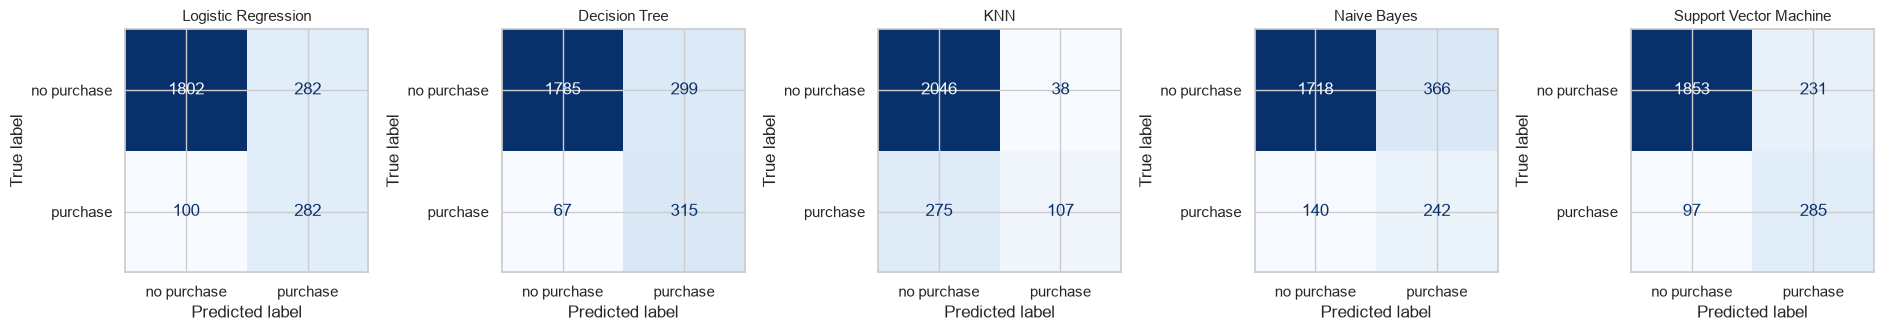

,TN,FP,FN,TP
ML Model Name,,,,
Logistic Regression,1802,282,100,282
Decision Tree,1785,299,67,315
KNN,2046,38,275,107
Naive Bayes,1718,366,140,242
Support Vector Machine,1853,231,97,285


In [22]:
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report, confusion_matrix,
                             roc_curve)

fig, axes = plt.subplots(1, 5, figsize=(19, 4))
cm_rows = {}
for ax, (name, model) in zip(axes, fitted.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    cm_rows[name] = {"TN": cm[0, 0], "FP": cm[0, 1], "FN": cm[1, 0], "TP": cm[1, 1]}
    ConfusionMatrixDisplay(cm, display_labels=["no purchase", "purchase"]).plot(
        ax=ax, colorbar=False, cmap="Blues", values_format="d")
    ax.set_title(name, fontsize=11)
plt.tight_layout()
fig.savefig(RESULTS_DIR / "confusion_matrices.png", dpi=120)
plt.show()

cm_table = pd.DataFrame(cm_rows).T
cm_table.index.name = "ML Model Name"
cm_table.to_csv(RESULTS_DIR / "confusion_matrices.csv")
cm_table

### 4.2 Classification reports

In [23]:
report_chunks = []
for name, model in fitted.items():
    rep = classification_report(y_test, model.predict(X_test),
                                target_names=["no purchase", "purchase"], digits=4)
    report_chunks.append(f"=== {name} ===\n{rep}")
    print(report_chunks[-1])
_ = (RESULTS_DIR / "classification_reports.txt").write_text("\n".join(report_chunks))

=== Logistic Regression ===
              precision    recall  f1-score   support

 no purchase     0.9474    0.8647    0.9042      2084
    purchase     0.5000    0.7382    0.5962       382

    accuracy                         0.8451      2466
   macro avg     0.7237    0.8015    0.7502      2466
weighted avg     0.8781    0.8451    0.8565      2466

=== Decision Tree ===
              precision    recall  f1-score   support

 no purchase     0.9638    0.8565    0.9070      2084
    purchase     0.5130    0.8246    0.6325       382

    accuracy                         0.8516      2466
   macro avg     0.7384    0.8406    0.7698      2466
weighted avg     0.8940    0.8516    0.8645      2466

=== KNN ===
              precision    recall  f1-score   support

 no purchase     0.8815    0.9818    0.9289      2084
    purchase     0.7379    0.2801    0.4061       382

    accuracy                         0.8731      2466
   macro avg     0.8097    0.6309    0.6675      2466
weighted avg

=== Support Vector Machine ===
              precision    recall  f1-score   support

 no purchase     0.9503    0.8892    0.9187      2084
    purchase     0.5523    0.7461    0.6347       382

    accuracy                         0.8670      2466
   macro avg     0.7513    0.8176    0.7767      2466
weighted avg     0.8886    0.8670    0.8747      2466



### 4.3 ROC curves and metric comparison

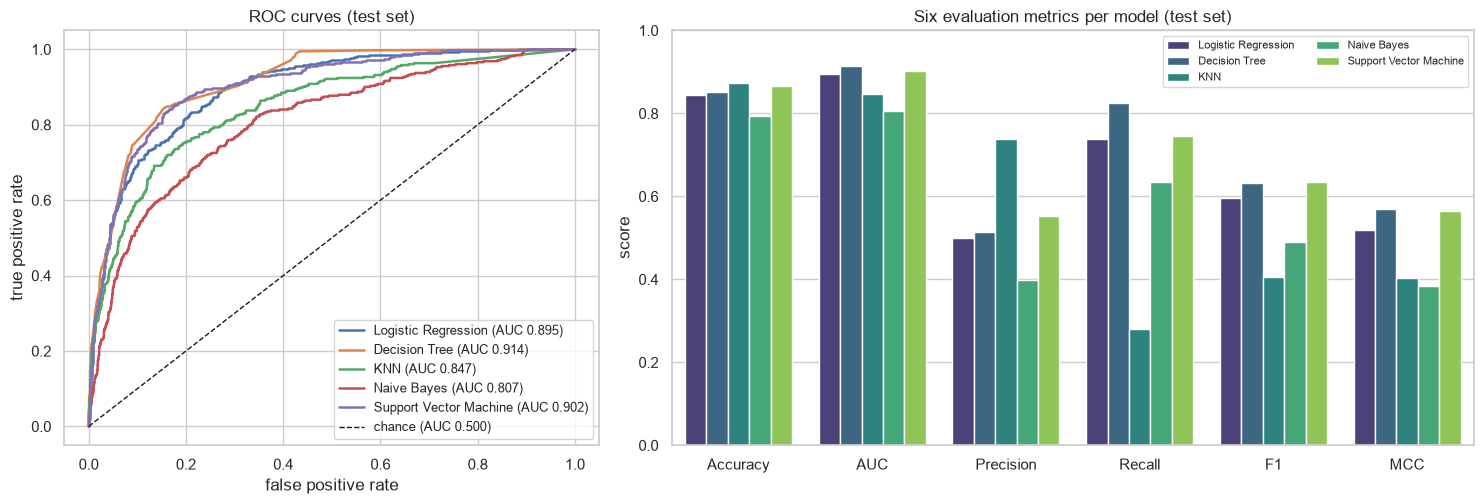

In [24]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1, 1.5]})

for name, model in fitted.items():
    fpr, tpr, _ = roc_curve(y_test, positive_scores(model, X_test))
    ax1.plot(fpr, tpr, lw=1.8, label=f"{name} (AUC {metrics.loc[name, 'AUC']:.3f})")
ax1.plot([0, 1], [0, 1], "k--", lw=1, label="chance (AUC 0.500)")
ax1.set(xlabel="false positive rate", ylabel="true positive rate", title="ROC curves (test set)")
ax1.legend(loc="lower right", fontsize=9)

long = metrics.reset_index().melt(id_vars="ML Model Name", var_name="metric", value_name="score")
sns.barplot(data=long, x="metric", y="score", hue="ML Model Name", ax=ax2, palette="viridis")
ax2.set(ylim=(0, 1), title="Six evaluation metrics per model (test set)", xlabel="", ylabel="score")
ax2.legend(fontsize=8, loc="upper right", ncol=2)
plt.tight_layout()
fig.savefig(RESULTS_DIR / "roc_and_metrics.png", dpi=120)
plt.show()

### 4.4 What drives the predictions?

Feature importances of the tuned decision tree (the strongest model on AUC and MCC) and the largest
absolute coefficients of the logistic regression.

In [25]:
tree = fitted["Decision Tree"]
names_out = tree.named_steps["prep"].get_feature_names_out()
imp = pd.Series(tree.named_steps["clf"].feature_importances_, index=names_out).sort_values(ascending=False)
lr = fitted["Logistic Regression"]
coef = pd.Series(lr.named_steps["clf"].coef_[0], index=lr.named_steps["prep"].get_feature_names_out())
coef_top = coef.reindex(coef.abs().sort_values(ascending=False).index)

print("Decision tree - top feature importances")
print(imp.head(8).round(4).to_string())
print("\nLogistic regression - largest |coefficients| (standardised / one-hot inputs)")
print(coef_top.head(8).round(3).to_string())
imp.to_csv(RESULTS_DIR / "tree_feature_importance.csv", header=["importance"])

Decision tree - top feature importances
PageValues                 0.8186
Month_Nov                  0.0641
ProductRelated_Duration    0.0307
Administrative_Duration    0.0167
Month_Sep                  0.0165
ExitRates                  0.0144
Month_May                  0.0110
Month_Mar                  0.0090

Logistic regression - largest |coefficients| (standardised / one-hot inputs)
PageValues        2.210
Month_Nov         0.703
ExitRates        -0.606
Month_Feb        -0.596
Month_May        -0.558
TrafficType_13   -0.517
Month_Sep         0.474
Month_Mar        -0.471


### 4.5 Observations

The observation text below is generated from `metrics.csv`, `metrics_default.csv` and the confusion
matrices, so every number quoted matches the saved results. It is written to `results/observations.md`
for the README.

In [26]:
m, b, c = metrics, baseline, cm_table
rank_mcc = m["MCC"].sort_values(ascending=False)
winner = rank_mcc.index[0]
runner = rank_mcc.index[1]
params = {n: tuning_rows[n]["best_params"] for n in m.index}

# --- facts quoted in the prose below, computed here so the text cannot drift from the data ---
default_tree = make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)).fit(X_train, y_train)
dt_train_acc = default_tree.score(X_train, y_train)
dt_depth = default_tree.named_steps["clf"].get_depth()
dt_leaves = default_tree.named_steps["clf"].get_n_leaves()
n_onehot = len(fitted["KNN"].named_steps["prep"].get_feature_names_out()) - len(NUMERIC_FEATURES)
dur_pairs = [("Administrative", "Administrative_Duration"), ("Informational", "Informational_Duration"),
             ("ProductRelated", "ProductRelated_Duration")]
corr_vals = [raw[count_col].corr(raw[dur_col]) for count_col, dur_col in dur_pairs]

def score_seconds(model, reps=5):
    best = float("inf")
    for _ in range(reps):
        t0 = time.perf_counter(); model.predict(X_test); best = min(best, time.perf_counter() - t0)
    return best
score_s = {n: score_seconds(mdl) for n, mdl in fitted.items()}
search_s = {n: tuning_rows[n]["search_s"] for n in m.index}

# every comparative claim made in the text is asserted here
assert b["fit_s"].idxmin() == "Naive Bayes", "Naive Bayes is no longer the fastest to fit"
assert max(search_s, key=search_s.get) == "Support Vector Machine", "SVM is not the slowest to tune"
assert max(score_s, key=score_s.get) == "Support Vector Machine", "SVM is not the slowest to score"
assert m["F1"].idxmax() == runner, "runner-up no longer has the best F1"
assert m["Accuracy"].idxmax() == "KNN" and m["Precision"].idxmax() == "KNN" and m["Recall"].idxmin() == "KNN"
assert imp.index[0] == "PageValues"

def row(name):
    return m.loc[name]

obs = {
"Logistic Regression": (
    f"Cross-validation picked strong regularisation (C={params['Logistic Regression']['C']}) with balanced class "
    f"weights. Recall rose from {b.loc['Logistic Regression','Recall']:.2f} (defaults) to {row('Logistic Regression')['Recall']:.2f} "
    f"and MCC from {b.loc['Logistic Regression','MCC']:.3f} to {row('Logistic Regression')['MCC']:.3f}, at the cost of "
    f"precision ({row('Logistic Regression')['Precision']:.2f}) and accuracy, which ends at {row('Logistic Regression')['Accuracy']:.1%} while always predicting 'no purchase' would score {majority_acc:.1%}. "
    f"AUC {row('Logistic Regression')['AUC']:.3f} shows the linear boundary ranks sessions well; `PageValues` dominates the "
    f"coefficients. A solid, fast and interpretable baseline, but the straight-line boundary limits it on this data."),
"Decision Tree": (
    f"A shallow tree (max_depth={params['Decision Tree']['max_depth']}, min_samples_leaf={params['Decision Tree']['min_samples_leaf']}, "
    f"balanced) is the strongest model: best AUC ({row('Decision Tree')['AUC']:.3f}), best recall ({row('Decision Tree')['Recall']:.2f}, "
    f"only {int(c.loc['Decision Tree','FN'])} of {int(y_test.sum())} purchases missed) and best MCC ({row('Decision Tree')['MCC']:.3f}). "
    f"The default unpruned tree memorises the training set (accuracy {dt_train_acc:.2f}, depth {dt_depth}, {dt_leaves} leaves) "
    f"but reaches only AUC {b.loc['Decision Tree','AUC']:.3f} on the test set, so depth and leaf-size limits were essential. "
    f"Splits are driven overwhelmingly by `PageValues` (importance {imp['PageValues']:.2f}); the next largest are a November visit "
    f"({imp['Month_Nov']:.2f}) and product-page duration ({imp['ProductRelated_Duration']:.2f}). The rules are easy to explain to a business user."),
"KNN": (
    f"k={params['KNN']['n_neighbors']} with distance weighting gives the highest accuracy ({row('KNN')['Accuracy']:.3f}) and "
    f"precision ({row('KNN')['Precision']:.2f}) but the lowest recall ({row('KNN')['Recall']:.2f}): it flags only "
    f"{int(c.loc['KNN','TP'] + c.loc['KNN','FP'])} sessions as purchases and misses {int(c.loc['KNN','FN'])} real ones. "
    f"{n_onehot} of the 75 scaled + one-hot inputs are binary columns, which probably blur the distances, so neighbourhoods are "
    f"noisy; KNN also has no class-weight option to correct the imbalance. Its AUC ({row('KNN')['AUC']:.3f}) is second-lowest, "
    f"ahead only of Naive Bayes, and tuning for AUC actually lowered its F1 ({row('KNN')['F1']:.3f} vs "
    f"{b.loc['KNN','F1']:.3f} with defaults)."),
"Naive Bayes": (
    f"Gaussian NB is the weakest model (AUC {row('Naive Bayes')['AUC']:.3f}, MCC {row('Naive Bayes')['MCC']:.3f}). Its "
    f"conditional-independence assumption is violated (page counts and their durations are correlated, r = {min(corr_vals):.2f} to {max(corr_vals):.2f}) and a Gaussian is a "
    f"poor fit for zero-inflated, right-skewed features and for one-hot columns. With the default var_smoothing it collapsed to "
    f"predicting 'purchase' almost everywhere (accuracy {b.loc['Naive Bayes','Accuracy']:.2f}, recall {b.loc['Naive Bayes','Recall']:.2f}); "
    f"var_smoothing={params['Naive Bayes']['var_smoothing']} repairs it to a usable but still inferior model. Its one advantage is "
    f"speed: it fits faster than every other model ({b.loc['Naive Bayes','fit_s']:.2f} s with defaults)."),
"Support Vector Machine": (
    f"The RBF SVM (C={params['Support Vector Machine']['C']}, gamma={params['Support Vector Machine']['gamma']}, balanced) is a close "
    f"second: best F1 ({row('Support Vector Machine')['F1']:.3f}), MCC {row('Support Vector Machine')['MCC']:.3f} and AUC "
    f"{row('Support Vector Machine')['AUC']:.3f}, with the best precision/recall balance among the recall-oriented models "
    f"({row('Support Vector Machine')['Precision']:.2f} / {row('Support Vector Machine')['Recall']:.2f}). Balanced weights lifted "
    f"recall from {b.loc['Support Vector Machine','Recall']:.2f} to {row('Support Vector Machine')['Recall']:.2f}. It is the slowest "
    f"model to tune ({search_s['Support Vector Machine']:.0f} s of cross-validated search) and to score, and it offers no direct interpretability."),
}
overall = (
    f"**{winner}** (tuned). It leads on the three metrics that matter under a 15 % positive rate: AUC "
    f"{row(winner)['AUC']:.3f}, recall {row(winner)['Recall']:.2f} and MCC {row(winner)['MCC']:.3f}, with F1 "
    f"{row(winner)['F1']:.3f} within {abs(row(winner)['F1'] - row(runner)['F1']):.3f} of the best. The {runner} is a close "
    f"second (MCC {row(runner)['MCC']:.3f}) but is much slower to tune and score and is a black box, while the tree's cross-validated "
    f"search took {search_s[winner]:.1f} s and its splits can be read directly. Accuracy would have crowned KNN, which misses "
    f"{int(c.loc['KNN','FN'])} of {int(y_test.sum())} purchases, a reminder that accuracy is the wrong yardstick on "
    f"imbalanced data."
)

lines = ["| ML Model Name | Observation about model performance |", "|---|---|"]
lines += [f"| {n} | {t} |" for n, t in obs.items()]
lines += [f"| **Overall, Winner for your dataset?** | {overall} |"]
observations_md = "\n".join(lines)
(RESULTS_DIR / "observations.md").write_text(observations_md + "\n")
for n, t in obs.items():
    print(f"{n}\n  {t}\n")
print(f"Overall winner\n  {overall}")

Logistic Regression
  Cross-validation picked strong regularisation (C=0.1) with balanced class weights. Recall rose from 0.36 (defaults) to 0.74 and MCC from 0.459 to 0.519, at the cost of precision (0.50) and accuracy, which ends at 84.5% while always predicting 'no purchase' would score 84.5%. AUC 0.895 shows the linear boundary ranks sessions well; `PageValues` dominates the coefficients. A solid, fast and interpretable baseline, but the straight-line boundary limits it on this data.

Decision Tree
  A shallow tree (max_depth=6, min_samples_leaf=20, balanced) is the strongest model: best AUC (0.914), best recall (0.82, only 67 of 382 purchases missed) and best MCC (0.570). The default unpruned tree memorises the training set (accuracy 1.00, depth 25, 803 leaves) but reaches only AUC 0.736 on the test set, so depth and leaf-size limits were essential. Splits are driven overwhelmingly by `PageValues` (importance 0.82); the next largest are a November visit (0.06) and product-page dur

### 4.6 Validation of the analysis artefacts

Every number cited in the observations is formatted from the metric tables, and the confusion matrix counts
must agree with the accuracy / recall values in `metrics.csv`.

In [27]:
for name in metrics.index:
    r = cm_table.loc[name]
    n = r.sum()
    assert n == len(y_test)
    assert np.isclose((r["TP"] + r["TN"]) / n, metrics.loc[name, "Accuracy"])
    assert np.isclose(r["TP"] / (r["TP"] + r["FN"]), metrics.loc[name, "Recall"])
    assert np.isclose(r["TP"] / (r["TP"] + r["FP"]), metrics.loc[name, "Precision"])
assert winner == metrics["MCC"].idxmax() == metrics["AUC"].idxmax(), "winner is not top on both MCC and AUC"
for f in ["confusion_matrices.png", "roc_and_metrics.png", "classification_reports.txt", "observations.md",
          "tree_feature_importance.csv", "confusion_matrices.csv"]:
    assert (RESULTS_DIR / f).stat().st_size > 0, f
print("confusion-matrix counts agree with metrics.csv; winner leads on both MCC and AUC; all artefacts written")

confusion-matrix counts agree with metrics.csv; winner leads on both MCC and AUC; all artefacts written
